<a href="https://colab.research.google.com/github/lazaroninamiguel-dot/mchv502-cuencas/blob/main/T06.1_deslizamiento/notebook/S09_1_Deslizamiento_Sumbay.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Semana 9 · Práctica 2 · SAT por deslizamiento: susceptibilidad de laderas
## Subcuenca del río Sumbay (Imata, Arequipa)

## 0. Identificación

| | |
|---|---|
| **Estudiante** | Miguel Ángel Lázaro Nina |
| **Curso** | MCHV-502 Programación y SIG para el análisis de cuencas · CATIE |
| **Docente** | Prof. Norman Ávila |
| **Práctica** | Semana 9 · Caso 2 · Riesgo por deslizamiento (adaptación de la práctica de clase al río Sumbay) |
| **Área de estudio** | Subcuenca del río Sumbay, 190,3 km², 4 489–5 036 m s. n. m. |
| **Insumos propios** | Cuenca (semana 5), DEM y WorldCover (semana 8), evento máximo CHIRPS 2015–2025 (semana 8), zonas a vigilar por inundación (práctica 1) |

**Idea central.** Una ladera falla cuando la lluvia vence lo que sostiene al suelo. Hay **factores condicionantes** que dicen *dónde* (pendiente, cobertura, cercanía al cauce) y un **factor detonante** que dice *cuándo* (la lluvia acumulada). La práctica 1 describía hasta dónde llega el agua; esta describe qué ladera puede fallar.

## 1. Configuración

In [1]:
#se debe instalar pysheds porque la maquina virtual que provee colab no la tiene
!pip install -q pysheds

In [2]:
#paso 0. - configurar el ambiente con lo necesario
import numpy as np

# pysheds usa np.in1d, retirada en NumPy 2. np.isin hace lo mismo.
if not hasattr(np, "in1d"):
    np.in1d = np.isin

import os
import pandas as pd  # Para el análisis y manipulación de datos en tablas (DataFrames)
import geopandas as gpd  # Para trabajar con datos vectoriales georreferenciados (GeoDataFrames)
import matplotlib.pyplot as plt  # Para la generación de gráficos y visualización de mapas
import rasterio  # Para leer, escribir y procesar imágenes y datos ráster de SIG
from rasterio import features  # Para rasterizar geometrías vectoriales o vectorizar rásters
from rasterio.transform import from_origin  # Para definir las coordenadas de origen y resolución del ráster
from rasterio.warp import reproject, Resampling  # Para reproyectar datos ráster a otros sistemas de coordenadas
from scipy import ndimage  # Para el procesamiento multidimensional de imágenes (filtros, distancias)
from shapely.geometry import shape  # Para crear y manipular geometrías vectoriales
from pysheds.grid import Grid  # Para el análisis hidrológico y cálculo de cuencas/acumulación

# Mi repositorio de GitHub (versión "raw", la que Python puede leer directamente)
BASE = "https://raw.githubusercontent.com/lazaroninamiguel-dot/mchv502-cuencas/main/"
UTM = "EPSG:32719"     # UTM 19 Sur, el huso de Arequipa
RES = 30               # metros por celda, la del DEM

# Productos de semanas anteriores
F_CUENCA = BASE + "T03_delimitacion/resultados/T03_micro_cuenca_imata_chili.geojson"   # semana 5
F_DEM    = BASE + "T05_escorrentia/insumos/S08_dem_imata.tif"                          # semana 8
F_COBER  = BASE + "T05_escorrentia/insumos/S08_worldcover_imata.tif"                   # semana 8
F_EVENTO = BASE + "T05_escorrentia/insumos/S08_evento_imata.csv"                       # semana 8: lluvia máxima CHIRPS
F_INUND  = BASE + "T06_inundacion/resultados/S09_zonas_a_vigilar_sumbay.csv"           # práctica 1 de esta semana

SALIDA = "S09_deslizamiento"          # carpeta de resultados de esta práctica
os.makedirs(SALIDA, exist_ok=True)
print("listo")

listo


## 2. Carga de datos

In [3]:
#preparar la malla
cuenca = gpd.read_file(F_CUENCA).to_crs(UTM)
print(f"Área de la cuenca: {cuenca.area.sum() / 1e6:.1f} km²")

# la malla: el recuadro de la cuenca con 300 m de margen
x0, y0, x1, y1 = cuenca.total_bounds
x0, y0, x1, y1 = x0 - 300, y0 - 300, x1 + 300, y1 + 300
ncol = int((x1 - x0) / RES)
nfil = int((y1 - y0) / RES)
transform = from_origin(x0, y1, RES, RES)

def a_la_malla(url, metodo):
    """Lee un ráster y lo lleva a la malla de trabajo."""
    destino = np.zeros((nfil, ncol), dtype="float32")
    with rasterio.open(url) as src:
        reproject(rasterio.band(src, 1), destino,
                  dst_transform=transform, dst_crs=UTM, resampling=metodo)
    return destino

dem = a_la_malla(F_DEM, Resampling.bilinear)                          # altitud: se promedia (bilinear)
cobertura = a_la_malla(F_COBER, Resampling.mode).astype("uint8")      # clases: se toma la más frecuente (mode)
en_cuenca = features.rasterize(cuenca.geometry, out_shape=dem.shape, transform=transform).astype(bool)
extent = (x0, x0 + ncol * RES, y1 - nfil * RES, y1)

def guardar_tif(arreglo, nombre, tipo="float32"):
    perfil = dict(driver="GTiff", height=nfil, width=ncol, count=1, dtype=tipo,
                  crs=UTM, transform=transform, nodata=-9999 if tipo == "float32" else 0)
    with rasterio.open(nombre, "w", **perfil) as dst:
        dst.write(arreglo.astype(tipo), 1)

guardar_tif(dem, "dem_utm.tif")
print(f"Malla: {nfil} filas x {ncol} columnas · altitud {dem[en_cuenca].min():.0f} a {dem[en_cuenca].max():.0f} m")

Área de la cuenca: 190.3 km²
Malla: 592 filas x 571 columnas · altitud 4489 a 5033 m


In [4]:
# Lluvia de referencia propia: el evento máximo de CHIRPS en la cuenca (semana 8)
evento = pd.read_csv(F_EVENTO).set_index("variable")["valor"]
REFERENCIA_MM = float(evento["max_3dias_mm"])            # mayor lluvia acumulada en 3 días, 2015–2025
print(f"Lluvia de referencia: {REFERENCIA_MM:.1f} mm en 3 días (ocurrió el {evento['fecha_fin_3dias']})")
display(evento.to_frame())

Lluvia de referencia: 93.6 mm en 3 días (ocurrió el 2018-05-05)


,valor
variable,
max_1dia_mm,93.6
fecha_1dia,2018-05-05
max_3dias_mm,93.6
fecha_fin_3dias,2018-05-05
media_anual_mm,626.3
periodo,2015-2025


## 3. Procesamiento

### 3.1 Paso 1 · Las tres capas condicionantes: pendiente, cobertura y distancia al cauce

In [5]:
#paso 1 calcular las 3 capas de la amenaza
#pendiente (Viene de DEM)
#cobertura (Viene de WorldCover)
#Distancia del cauce (pysheds / red de drenaje)

# 1. Inicializa una malla de Pysheds a partir del DEM local
grid = Grid.from_raster("dem_utm.tif")
# 2. Lee los datos de elevación del DEM
dem_g = grid.read_raster("dem_utm.tif")
# 3. Corrige pozos, depresiones y planicies para que el agua ficticia fluya sin estancarse (semana 4)
dem_lleno = grid.resolve_flats(grid.fill_depressions(grid.fill_pits(dem_g)))
# 4. Dirección de flujo D8: hacia qué celda vecina baja el agua
direccion = grid.flowdir(dem_lleno)
# 5. Acumulación: cuántas celdas aguas arriba aportan a cada celda
acumulacion = np.array(grid.accumulation(direccion))

# 6. Cauce: celdas con más de 1000 celdas de aporte (~0.9 km²), dentro de la cuenca
cauce = (acumulacion > 1000) & en_cuenca
# 7. Distancia euclidiana (m) de cada celda al cauce más cercano
dist_cauce = ndimage.distance_transform_edt(~cauce) * RES
# 8. Gradientes de altitud en y y en x
gy, gx = np.gradient(dem, RES)
# 9. Pendiente en grados
pendiente = np.degrees(np.arctan(np.hypot(gx, gy)))
# 10. Control
print(f"Celdas de cauce: {cauce.sum():,} · pendiente media de la cuenca: {pendiente[en_cuenca].mean():.1f}° · máxima: {pendiente[en_cuenca].max():.0f}°")

Celdas de cauce: 4,367 · pendiente media de la cuenca: 5.6° · máxima: 42°


In [6]:
#reclasificacion
# 1. Pendiente en rangos de susceptibilidad (1 a 5): a mayor inclinación, más fácil que el suelo se desprenda
c_pendiente = np.select(
    [pendiente < 5, pendiente < 15, pendiente < 25, pendiente < 35],  # Límites de corte en grados
    [1, 2, 3, 4],  # Puntajes asignados correspondientes
    default=5)     # Las pendientes de 35 grados o más reciben el puntaje máximo de 5

ha = RES * RES / 1e4          # una celda de 30 m = 0,09 ha
pd.DataFrame({"puntaje": [1, 2, 3, 4, 5],
              "pendiente": ["< 5°", "5–15°", "15–25°", "25–35°", "> 35°"],
              "area_ha": [(c_pendiente[en_cuenca] == k).sum() * ha for k in range(1, 6)]}).round(0)

,puntaje,pendiente,area_ha
0,1,< 5°,10861.0
1,2,5–15°,7225.0
2,3,15–25°,877.0
3,4,25–35°,70.0
4,5,> 35°,4.0


#### Cobertura: el mismo criterio del profesor, con las clases que hay en la puna

En el Sumbay no hay bosque ni cultivos. Sí hay dos clases que no aparecían en Atitlán: **bofedal (90)**, que es suelo saturado y plano, y mucho **suelo desnudo / vegetación rala (60)**, que no tiene raíces que lo amarren.

In [8]:
# 2. Diccionario que asocia los códigos de WorldCover con un nivel de susceptibilidad física
puntaje_cobertura = {
    10: 1,   # Árboles (bosques): las raíces amarran el suelo (no hay en el Sumbay)
    20: 2,   # Arbustos: susceptibilidad baja
    30: 3,   # Pastizal (pajonal de puna): raíces superficiales, susceptibilidad media
    40: 4,   # Cultivos: suelo arado sin raíces profundas (no hay en el Sumbay)
    50: 2,   # Construido: superficies compactadas
    60: 5,   # Suelo desnudo / vegetación rala: ninguna barrera vegetal contra la erosión
    80: 1,   # Cuerpos de agua: no son ladera
    90: 1    # Bofedal / humedal: terreno plano y saturado, no se desprende
}

# 3. Aplica el diccionario celda por celda; si aparece una clase no listada, recibe 3 (medio)
c_cobertura = np.vectorize(lambda v: puntaje_cobertura.get(int(v), 3))(cobertura)

In [9]:
# 4. Proximidad a los ríos: a menor distancia, mayor susceptibilidad por socavamiento del pie de la ladera
c_cauce = np.select(
    [dist_cauce < 50, dist_cauce < 100, dist_cauce < 200, dist_cauce < 400], # Zonas de amortiguamiento en metros
    [5, 4, 3, 2],  # Puntajes que disminuyen con la distancia al agua
    default=1)     # Distancias mayores a 400 metros se consideran seguras (puntaje 1)

# Tabla resumen de control de las tres reclasificaciones
pd.DataFrame({
    "puntaje": [1, 2, 3, 4, 5],
    "pendiente": ["< 5°", "5–15°", "15–25°", "25–35°", "> 35°"],
    "cobertura": ["bofedal, agua", "arbustos, construido", "pastizal", "cultivos", "suelo desnudo / veg. rala"],
    "distancia al cauce": ["> 400 m", "200–400 m", "100–200 m", "50–100 m", "< 50 m"]
})

,puntaje,pendiente,cobertura,distancia al cauce
0,1,< 5°,"bofedal, agua",> 400 m
1,2,5–15°,"arbustos, construido",200–400 m
2,3,15–25°,pastizal,100–200 m
3,4,25–35°,cultivos,50–100 m
4,5,> 35°,suelo desnudo / veg. rala,< 50 m


### 3.2 Paso 2 · Álgebra de mapas: la susceptibilidad y sus clases

In [12]:
#Paso 2 algebra de mapas: suma ponderada de las tres capas
# 50 % pendiente (fuerza motriz), 30 % cobertura (cohesión), 20 % cauce (erosión basal)
PESOS = {"pendiente": 0.5, "cobertura": 0.3, "cauce": 0.2}

# Como los pesos suman 1, la susceptibilidad queda en la misma escala de 1 a 5
susceptibilidad = (PESOS["pendiente"] * c_pendiente
                   + PESOS["cobertura"] * c_cobertura
                   + PESOS["cauce"] * c_cauce)

# Clases discretas con los umbrales del curso
clase = np.select([susceptibilidad < 2, susceptibilidad < 3, susceptibilidad < 3.5], [1, 2, 3], default=4)
nombres = {1: "baja", 2: "media", 3: "alta", 4: "muy alta"}

resumen = pd.DataFrame({"clase": list(nombres.values()),
                        "area_ha": [(clase[en_cuenca] == k).sum() * ha for k in nombres]})
resumen["%_cuenca"] = (resumen.area_ha / resumen.area_ha.sum() * 100).round(1)
resumen.round(0)

,clase,area_ha,%_cuenca
0,baja,2562.0,14.0
1,media,13980.0,73.0
2,alta,2045.0,11.0
3,muy alta,450.0,2.0


In [13]:
# ¿Qué cobertura tienen las laderas de susceptibilidad alta y muy alta?
nombres_cob = {30: "Pastizal", 60: "Veg. rala / suelo desnudo", 80: "Agua", 90: "Bofedal"}
pd.DataFrame({"cobertura": list(nombres_cob.values()),
              "alta_o_muy_alta_ha": [((clase >= 3) & (cobertura == k) & en_cuenca).sum() * ha for k in nombres_cob]}).round(0)

,cobertura,alta_o_muy_alta_ha
0,Pastizal,117.0
1,Veg. rala / suelo desnudo,2379.0
2,Agua,0.0
3,Bofedal,0.0


### 3.3 Pasos 3 y 4 · Amenaza, vulnerabilidad y riesgo

Según las diapositivas del curso, para el deslizamiento **basta con estar al pie de la ladera**: a cada celda se le asigna la susceptibilidad **más alta que haya a 150 m** a su alrededor (`maximum_filter`). Esa es la amenaza. La vulnerabilidad es la misma de la práctica 1, adaptada a la puna (pastizal 3, bofedal 2, resto 1, construido 5).

In [15]:
# Paso 3: amenaza = susceptibilidad máxima en un círculo de 150 m de radio (5 celdas) alrededor de cada celda
r = 150 // RES                                                    # radio en celdas
yy, xx = np.ogrid[-r:r + 1, -r:r + 1]                             # cuadrícula centrada en la celda
circulo = (xx**2 + yy**2) <= r**2                                 # máscara circular: True dentro del radio
amenaza = ndimage.maximum_filter(susceptibilidad, footprint=circulo)

# Vulnerabilidad: la misma tabla de la práctica 1 (adaptada a la cabecera altoandina)
vulnerabilidad = np.select([cobertura == 50, cobertura == 30, cobertura == 90], [5, 3, 2], default=1)

# Paso 4: riesgo = amenaza × vulnerabilidad (1 a 25) y semáforo
riesgo = amenaza * vulnerabilidad
semaforo = np.select([riesgo >= 16, riesgo >= 6], [3, 2], default=1)    # 1 bajo, 2 medio, 3 alto

tabla_riesgo = pd.DataFrame({"riesgo": ["bajo (1–5)", "medio (6–15)", "alto (16–25)"],
                             "area_ha": [(semaforo[en_cuenca] == k).sum() * ha for k in (1, 2, 3)],
                             "pastizal_ha": [((semaforo == k) & (cobertura == 30) & en_cuenca).sum() * ha for k in (1, 2, 3)]})
tabla_riesgo["%_cuenca"] = (100 * tabla_riesgo.area_ha / tabla_riesgo.area_ha.sum()).round(1)
print(f"Riesgo máximo en la cuenca: {riesgo[en_cuenca].max():.1f}")
tabla_riesgo.round(0)

Riesgo máximo en la cuenca: 12.9


,riesgo,area_ha,pastizal_ha,%_cuenca
0,bajo (1–5),12823.0,51.0,67.0
1,medio (6–15),6214.0,6214.0,33.0
2,alto (16–25),0.0,0.0,0.0


## 4. Visualización

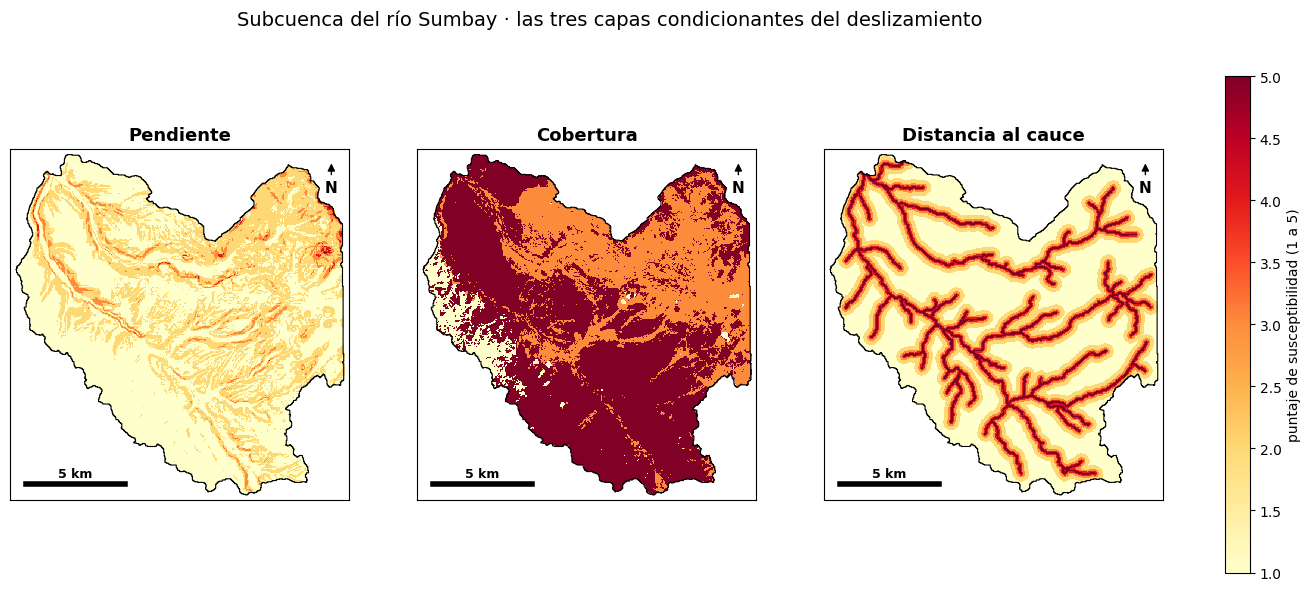

In [16]:
def barra_escala(ax, km=5):
    """Barra de escala de `km` kilómetros y flecha del norte."""
    xa, ya = extent[0] + 800, extent[2] + 800
    ax.plot([xa, xa + km * 1000], [ya, ya], color="black", lw=4)
    ax.text(xa + km * 500, ya + 350, f"{km} km", ha="center", fontsize=9, fontweight="bold")
    ax.annotate("N", xy=(extent[1] - 900, extent[3] - 600), xytext=(extent[1] - 900, extent[3] - 2200),
                ha="center", fontsize=11, fontweight="bold", arrowprops=dict(arrowstyle="-|>", color="black"))

fig, axs = plt.subplots(1, 3, figsize=(16, 6.5))
for ax, capa_, titulo in zip(axs, [c_pendiente, c_cobertura, c_cauce], ["Pendiente", "Cobertura", "Distancia al cauce"]):
    im = ax.imshow(np.where(en_cuenca, capa_, np.nan), cmap="YlOrRd", vmin=1, vmax=5, extent=extent, interpolation="nearest")
    cuenca.boundary.plot(ax=ax, color="black", lw=0.8)
    barra_escala(ax)
    ax.set_title(titulo, fontsize=13, fontweight="bold"); ax.set_xticks([]); ax.set_yticks([]); ax.set_xlabel(""); ax.set_ylabel("")
fig.colorbar(im, ax=axs, fraction=0.02, label="puntaje de susceptibilidad (1 a 5)")
fig.suptitle("Subcuenca del río Sumbay · las tres capas condicionantes del deslizamiento", fontsize=14)
plt.show()

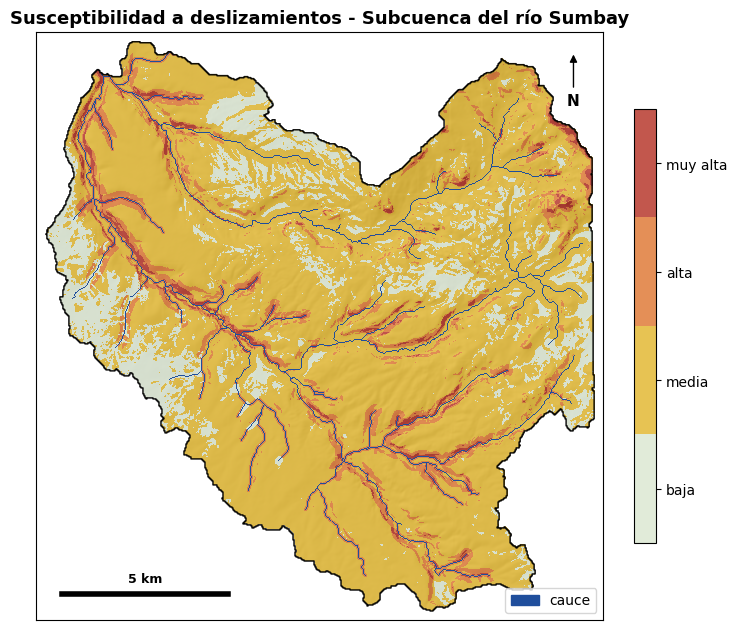

In [17]:
from matplotlib.colors import ListedColormap, LightSource
from matplotlib.patches import Patch
sombra = LightSource(315, 40).hillshade(dem, vert_exag=2, dx=RES, dy=RES)
colores = ListedColormap(["#DCE8D3", "#E3B935", "#E07B39", "#B83A2E"])

fig, ax = plt.subplots(figsize=(8, 9))
ax.imshow(np.where(en_cuenca, sombra, np.nan), cmap="gray", extent=extent)
im = ax.imshow(np.where(en_cuenca, clase, np.nan), cmap=colores, vmin=0.5, vmax=4.5, alpha=0.85, extent=extent, interpolation="nearest")
ax.imshow(np.where(cauce, 1, np.nan), cmap=ListedColormap(["#1f4e9c"]), extent=extent, interpolation="nearest")
cuenca.boundary.plot(ax=ax, color="black", lw=1)
barra_escala(ax)
cb = fig.colorbar(im, ax=ax, ticks=[1, 2, 3, 4], fraction=0.035); cb.ax.set_yticklabels(list(nombres.values()))
ax.legend(handles=[Patch(color="#1f4e9c", label="cauce")], loc="lower right")
ax.set_title("Susceptibilidad a deslizamientos - Subcuenca del río Sumbay", fontsize=13, fontweight="bold")
ax.set_xticks([]); ax.set_yticks([]); ax.set_xlabel(""); ax.set_ylabel("")
plt.show()

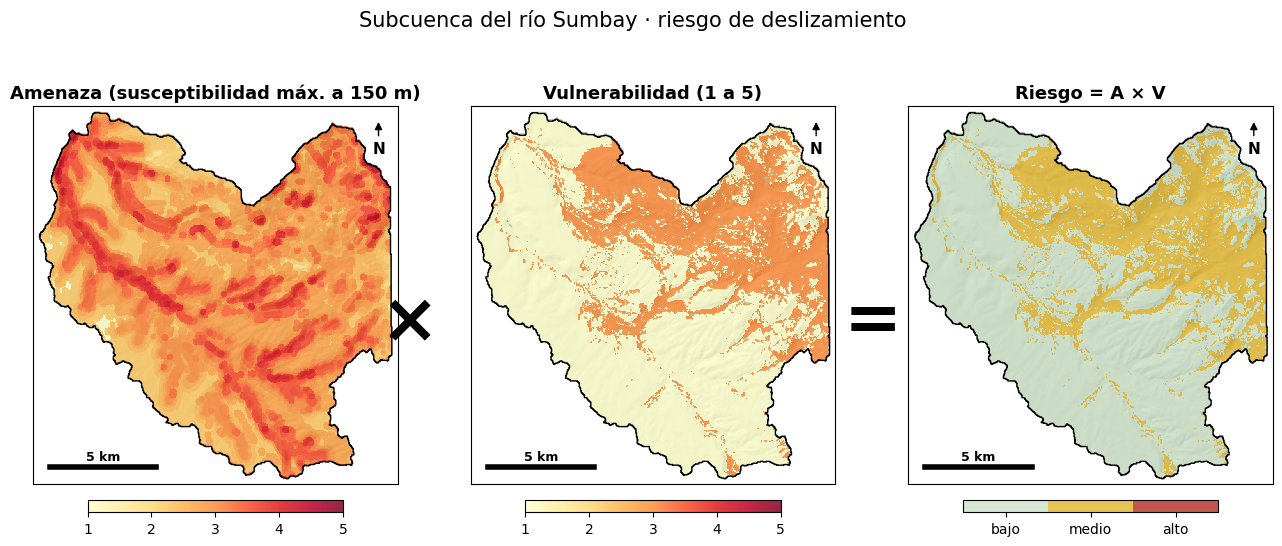

In [18]:
colores_semaforo = ListedColormap(["#CFE3C9", "#E3B935", "#B83A2E"])
fig, axs = plt.subplots(1, 3, figsize=(16, 6.5))
capas = [(amenaza, "Amenaza (susceptibilidad máx. a 150 m)", "YlOrRd", 1, 5),
         (vulnerabilidad, "Vulnerabilidad (1 a 5)", "YlOrRd", 1, 5),
         (semaforo, "Riesgo = A × V", colores_semaforo, 0.5, 3.5)]
for ax, (arr, t, cm, v0, v1) in zip(axs, capas):
    ax.imshow(np.where(en_cuenca, sombra, np.nan), cmap="gray", extent=extent)
    im = ax.imshow(np.where(en_cuenca, arr, np.nan), cmap=cm, vmin=v0, vmax=v1, alpha=0.85, extent=extent, interpolation="nearest")
    cuenca.boundary.plot(ax=ax, color="black", lw=1)
    ax.set_title(t, fontsize=13, fontweight="bold"); ax.set_xticks([]); ax.set_yticks([]); ax.set_xlabel(""); ax.set_ylabel("")
    if t.startswith("Riesgo"):
        cb = fig.colorbar(im, ax=ax, orientation="horizontal", shrink=0.7, pad=0.03, ticks=[1, 2, 3]); cb.ax.set_xticklabels(["bajo", "medio", "alto"])
    else:
        fig.colorbar(im, ax=ax, orientation="horizontal", shrink=0.7, pad=0.03, ticks=[1, 2, 3, 4, 5])
    barra_escala(ax)
fig.text(0.36, 0.5, "×", fontsize=50, ha="center", va="center", fontweight="bold")
fig.text(0.65, 0.5, "=", fontsize=50, ha="center", va="center", fontweight="bold")
fig.suptitle("Subcuenca del río Sumbay · riesgo de deslizamiento", fontsize=15)
plt.show()

### Lugares a vigilar

El profesor busca manchas construidas de al menos 1 ha y mide qué parte de su anillo de 150 m es ladera susceptible. En el Sumbay **WorldCover no detecta construcciones**, así que el foco pasa a lo que sí hay: **pastizal al pie de laderas de susceptibilidad muy alta** (riesgo ≥ 10,5 = vulnerabilidad 3 × amenaza ≥ 3,5). Si en el futuro hubiera celdas de riesgo alto, el código las toma primero.

In [21]:
#función de la práctica 1 para georeferencia inversa
import time
import requests

def lugar_cercano(lat, lon):
    """Nombre del caserío, anexo o lugar en (lat, lon), según OpenStreetMap."""
    try:
        r = requests.get("https://nominatim.openstreetmap.org/reverse",
                         params={"lat": lat, "lon": lon, "format": "jsonv2", "zoom": 14, "accept-language": "es"},
                         headers={"User-Agent": "curso-CATIE-MCHV502"}, timeout=20)
        a = r.json().get("address", {})
    except Exception:
        return "sin respuesta", ""
    time.sleep(1)                                    # regla de Nominatim: una consulta por segundo
    lugar = next((a[k] for k in ["hamlet", "village", "isolated_dwelling", "farm", "locality", "neighbourhood",
                                  "suburb", "town", "city", "road", "water", "natural"] if k in a), "sin nombre")
    municipio = a.get("municipality") or a.get("city") or a.get("town") or a.get("county", "")
    return lugar, municipio

In [22]:
foco = (semaforo == 3) & en_cuenca
criterio = "riesgo alto"
if foco.sum() == 0:                                   # sin construido no hay riesgo alto: se vigila el pastizal al pie de laderas muy susceptibles
    foco = (vulnerabilidad >= 3) & (amenaza >= 3.5) & en_cuenca
    criterio = "pastizal al pie de laderas de susceptibilidad muy alta"

# 1. Agrupamiento espacial: cada mancha continua de celdas en foco es un lugar
manchas, n = ndimage.label(foco)
filas = []
for i in range(1, n + 1):
    m = manchas == i
    if m.sum() < 11:                                  # ignora manchas menores a ~1 ha
        continue
    f, c = np.argwhere(m).mean(axis=0)                # centroide (fila, columna)
    anillo = ndimage.binary_dilation(m, iterations=150 // RES) & en_cuenca     # entorno de 150 m
    filas.append({"fila": f, "col": c, "area_ha": m.sum() * ha,
                  "%_anillo_muy_alta": (anillo & (clase == 4)).sum() / anillo.sum() * 100,
                  "pendiente_max_anillo": pendiente[anillo].max()})

manchas_df = pd.DataFrame(filas).sort_values("area_ha", ascending=False)
top = manchas_df.head(12).copy()

# 2. De (fila, col) a UTM y de UTM a lat/lon
x, y = rasterio.transform.xy(transform, top.fila.values, top.col.values)
centros = gpd.GeoSeries(gpd.points_from_xy(x, y), crs=UTM).to_crs("EPSG:4326")
top["lat"] = centros.y.round(4).values
top["lon"] = centros.x.round(4).values
print(f"{len(manchas_df)} manchas de {criterio} de al menos 1 ha ({manchas_df.area_ha.sum():.0f} ha); consultando nombres de las 12 mayores...")

# 3. Geocodificación inversa con Nominatim; si no responde, el lugar se llama por su número
nombres_lugar = [lugar_cercano(la, lo) for la, lo in zip(top.lat, top.lon)]
top["lugar"] = [nl[0] if nl[0] not in ("sin respuesta", "sin nombre") else f"Zona {i}" for i, nl in enumerate(nombres_lugar, start=1)]
top["municipio"] = [nl[1] for nl in nombres_lugar]
lugares = top[["lugar", "municipio", "lat", "lon", "area_ha", "%_anillo_muy_alta", "pendiente_max_anillo"]].reset_index(drop=True)
lugares = lugares.round({"area_ha": 1, "%_anillo_muy_alta": 1, "pendiente_max_anillo": 1})   # lat/lon se quedan con 4 decimales
lugares.index = lugares.index + 1
lugares

110 manchas de pastizal al pie de laderas de susceptibilidad muy alta de al menos 1 ha (817 ha); consultando nombres de las 12 mayores...


,lugar,municipio,lat,lon,area_ha,%_anillo_muy_alta,pendiente_max_anillo
1,Pucalacala,,-15.9286,-70.9554,84.1,3.7,22.500000
2,Llallahui,,-15.9079,-70.8775,45.0,3.8,23.700001
3,Llallahui,,-15.9207,-70.8912,44.0,5.8,28.600000
4,Cacahuasi,,-15.9356,-70.8993,39.4,3.5,29.799999
5,Pucacancha,San Juan de Tarucani,-15.9607,-70.8926,36.5,10.9,24.900000
6,Pucacancha,San Juan de Tarucani,-15.9564,-70.9038,30.7,10.3,20.900000
7,Pucacancha,San Juan de Tarucani,-15.9557,-70.9156,21.9,5.3,19.500000
8,Tacune,,-15.9194,-70.8620,19.8,4.6,23.700001
9,San Juan de Tarucani,San Juan de Tarucani,-15.9668,-70.9308,19.1,2.7,15.400000
10,Toriane,San Juan de Tarucani,-15.9536,-70.8835,18.6,4.4,23.700001


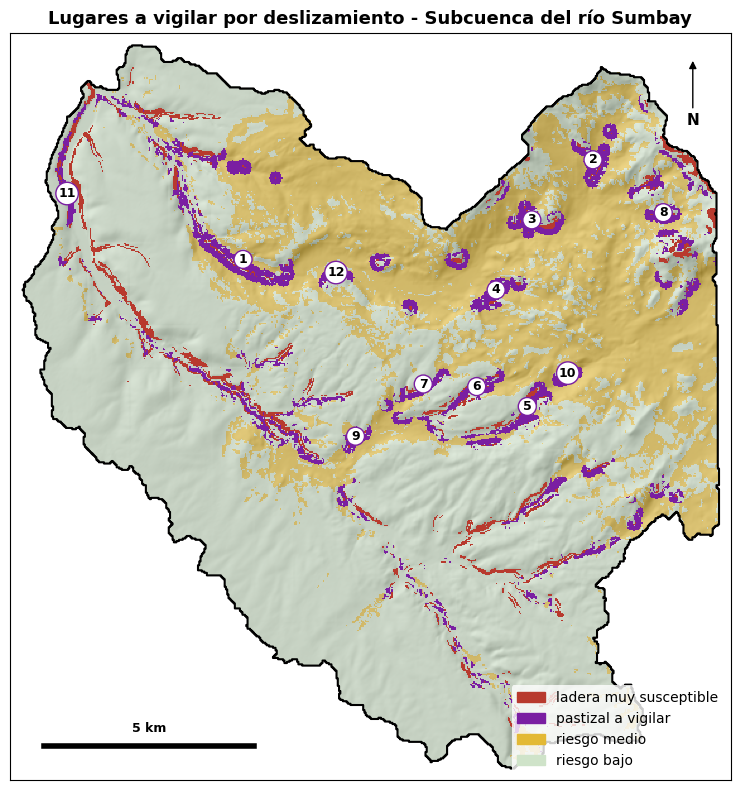

In [23]:
# Mapa de los lugares a vigilar sobre el semáforo
fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(np.where(en_cuenca, sombra, np.nan), cmap="gray", extent=extent)
ax.imshow(np.where(en_cuenca, semaforo, np.nan), cmap=colores_semaforo, vmin=0.5, vmax=3.5, alpha=0.6, extent=extent, interpolation="nearest")
ax.imshow(np.where((clase == 4) & en_cuenca, 1, np.nan), cmap=ListedColormap(["#B83A2E"]), extent=extent, interpolation="nearest")
ax.imshow(np.where(foco, 1, np.nan), cmap=ListedColormap(["#7a1fa2"]), extent=extent, interpolation="nearest")
cuenca.boundary.plot(ax=ax, color="black", lw=1.5)
for i, (xx, yy) in enumerate(zip(x, y), start=1):
    ax.annotate(str(i), (xx, yy), color="black", fontsize=9, fontweight="bold", ha="center",
                bbox=dict(boxstyle="circle,pad=0.2", fc="white", ec="#7a1fa2"))
barra_escala(ax)
ax.set_xticks([]); ax.set_yticks([]); ax.set_xlabel(""); ax.set_ylabel("")
ax.set_title("Lugares a vigilar por deslizamiento - Subcuenca del río Sumbay", fontsize=13, fontweight="bold")
ax.legend(handles=[Patch(color="#B83A2E", label="ladera muy susceptible"), Patch(color="#7a1fa2", label="pastizal a vigilar"),
                   Patch(color="#E3B935", label="riesgo medio"), Patch(color="#CFE3C9", label="riesgo bajo")],
          loc="lower right", frameon=True, facecolor="white", edgecolor="none")
plt.tight_layout()
plt.show()

### El pronóstico: ¿cuándo vigilar?

En Atitlán la referencia son los 250 mm que desencadenaron Panabaj (2005). En el Sumbay no hay un deslizamiento documentado, así que uso **la mayor lluvia de 3 días registrada por CHIRPS en la cuenca entre 2015 y 2025** (semana 8). Menos de la mitad: vigilancia baja; de la mitad a la referencia: media; más: alta.

In [24]:
# Pronóstico real de Open-Meteo para el centroide de la cuenca (igual que en la práctica 1)
centro = cuenca.to_crs("EPSG:4326").geometry.union_all().centroid if hasattr(cuenca.geometry, "union_all") \
         else cuenca.to_crs("EPSG:4326").unary_union.centroid
LAT, LON = round(centro.y, 3), round(centro.x, 3)
PRONOSTICO_MM = 24.8                                   # respaldo: evento de la semana 8
try:
    r = requests.get("https://api.open-meteo.com/v1/forecast", timeout=15, params={
        "latitude": LAT, "longitude": LON, "daily": "precipitation_sum",
        "forecast_days": 3, "timezone": "America/Lima"}).json()
    display(pd.DataFrame(r["daily"]))
    PRONOSTICO_MM = sum(r["daily"]["precipitation_sum"])
    print(f"Pronóstico real para 72 h: {PRONOSTICO_MM:.1f} mm")
except Exception:
    print(f"Sin conexión con Open-Meteo; se usa el escenario de {PRONOSTICO_MM} mm")
#PRONOSTICO_MM = 100   # quita el # para probar el sistema con una tormenta

,time,precipitation_sum
0,2026-11-11,5.3
1,2026-11-12,15.3
2,2026-11-13,11.6


Pronóstico real para 72 h: 32.2 mm


In [25]:
#la susceptibilidad dice el DÓNDE; el pronóstico dice el CUÁNDO
if PRONOSTICO_MM >= REFERENCIA_MM:
    vigilancia = "ALTA: recorrer los lugares de la lista y alejar el ganado del pie de las laderas"
elif PRONOSTICO_MM >= REFERENCIA_MM / 2:
    vigilancia = "MEDIA: vigilar los lugares de la lista (grietas, ruidos, agua turbia en quebradas)"
else:
    vigilancia = "BAJA: sin acción especial por lluvia"

lista = "\n".join(f"  {i}. {r.lugar} ({r.municipio}): {r.area_ha:.0f} ha de pastizal, {r._6:.0f} % del entorno en susceptibilidad muy alta"
                  for i, r in enumerate(lugares.head(6).itertuples(), start=1))
aviso = f"""SUBCUENCA DEL RÍO SUMBAY (IMATA) · LADERAS
Pronóstico: {PRONOSTICO_MM:.1f} mm en 72 horas ({PRONOSTICO_MM / REFERENCIA_MM:.0%} de la lluvia máxima registrada, {REFERENCIA_MM:.0f} mm en 3 días)
Vigilancia: {vigilancia}

Lugares a vigilar ({criterio}):
{lista}

Mapa de susceptibilidad calculado en clase, sin validar con deslizamientos reales; no es una alerta oficial."""
print(aviso)

SUBCUENCA DEL RÍO SUMBAY (IMATA) · LADERAS
Pronóstico: 32.2 mm en 72 horas (34% de la lluvia máxima registrada, 94 mm en 3 días)
Vigilancia: BAJA: sin acción especial por lluvia

Lugares a vigilar (pastizal al pie de laderas de susceptibilidad muy alta):
  1. Pucalacala (): 84 ha de pastizal, 4 % del entorno en susceptibilidad muy alta
  2. Llallahui (): 45 ha de pastizal, 4 % del entorno en susceptibilidad muy alta
  3. Llallahui (): 44 ha de pastizal, 6 % del entorno en susceptibilidad muy alta
  4. Cacahuasi (): 39 ha de pastizal, 4 % del entorno en susceptibilidad muy alta
  5. Pucacancha (San Juan de Tarucani): 36 ha de pastizal, 11 % del entorno en susceptibilidad muy alta
  6. Pucacancha (San Juan de Tarucani): 31 ha de pastizal, 10 % del entorno en susceptibilidad muy alta

Mapa de susceptibilidad calculado en clase, sin validar con deslizamientos reales; no es una alerta oficial.


### Para pensar (preguntas del profesor)

1. **Pesos 0,4 / 0,4 / 0,2:** ¿cambia la lista si la cobertura pesa tanto como la pendiente?
2. **Comparación con el caso 1:** ¿qué lugares aparecen en las dos listas, inundación y deslizamiento?

In [26]:
# 1. Sensibilidad a los pesos: 0.4 pendiente, 0.4 cobertura, 0.2 cauce
susc_b = 0.4 * c_pendiente + 0.4 * c_cobertura + 0.2 * c_cauce
clase_b = np.select([susc_b < 2, susc_b < 3, susc_b < 3.5], [1, 2, 3], default=4)
comparacion = pd.DataFrame({"clase": list(nombres.values()),
                            "pesos 0.5/0.3/0.2 (ha)": [(clase[en_cuenca] == k).sum() * ha for k in nombres],
                            "pesos 0.4/0.4/0.2 (ha)": [(clase_b[en_cuenca] == k).sum() * ha for k in nombres]}).round(0)
comparacion["cambio_ha"] = comparacion.iloc[:, 2] - comparacion.iloc[:, 1]
comparacion

,clase,pesos 0.5/0.3/0.2 (ha),pesos 0.4/0.4/0.2 (ha),cambio_ha
0,baja,2562.0,2061.0,-501.0
1,media,13980.0,10247.0,-3733.0
2,alta,2045.0,5807.0,3762.0
3,muy alta,450.0,923.0,473.0


In [27]:
# 2. Lugares que aparecen en las dos listas (inundación, práctica 1, y deslizamiento, esta práctica)
inundacion = pd.read_csv(F_INUND)
en_ambas = sorted(set(inundacion.lugar) & set(lugares.lugar))
print("Lugares en la lista de inundación:  ", ", ".join(inundacion.lugar))
print("Lugares en la lista de deslizamiento:", ", ".join(lugares.lugar.unique()))
print("En las dos listas:", ", ".join(en_ambas) if en_ambas else "ninguno")

Lugares en la lista de inundación:   Toriane, San Juan de Tarucani, Cacahuasi, Pucatara, Pucacancha, Pucalacala
Lugares en la lista de deslizamiento: Pucalacala, Llallahui, Cacahuasi, Pucacancha, Tacune, San Juan de Tarucani, Toriane, San Antonio de Chuca, Pucatara
En las dos listas: Cacahuasi, Pucacancha, Pucalacala, Pucatara, San Juan de Tarucani, Toriane


In [28]:
# Exportar: GeoTIFF de amenaza, vulnerabilidad y riesgo; GeoJSON de susceptibilidad alta y de los lugares; CSV y aviso
def a_poligonos(mascara, nombre):
    geoms = [shape(g) for g, v in features.shapes(mascara.astype("uint8"), transform=transform) if v == 1]
    gdf = gpd.GeoDataFrame({"capa": [nombre] * len(geoms)}, geometry=geoms, crs=UTM)
    gdf["area_ha"] = (gdf.area / 1e4).round(2)
    return gdf

guardar_tif(susceptibilidad, f"{SALIDA}/S09_susceptibilidad_sumbay.tif")
guardar_tif(clase, f"{SALIDA}/S09_susceptibilidad_clases_sumbay.tif", tipo="uint8")
guardar_tif(amenaza, f"{SALIDA}/S09_amenaza_deslizamiento_sumbay.tif")
guardar_tif(vulnerabilidad, f"{SALIDA}/S09_vulnerabilidad_sumbay.tif", tipo="uint8")
guardar_tif(semaforo, f"{SALIDA}/S09_semaforo_deslizamiento_sumbay.tif", tipo="uint8")
a_poligonos((clase >= 3) & en_cuenca, "susceptibilidad alta o muy alta").to_file(f"{SALIDA}/S09_susceptibilidad_alta_sumbay.geojson", driver="GeoJSON")
a_poligonos(foco, criterio).to_file(f"{SALIDA}/S09_zonas_a_vigilar_deslizamiento_sumbay.geojson", driver="GeoJSON")
gpd.GeoDataFrame(lugares, geometry=gpd.points_from_xy(lugares.lon, lugares.lat), crs="EPSG:4326").to_file(f"{SALIDA}/S09_lugares_laderas_sumbay.geojson", driver="GeoJSON")
lugares.to_csv(f"{SALIDA}/S09_lugares_laderas_sumbay.csv", index_label="orden")
resumen.round(1).to_csv(f"{SALIDA}/S09_resumen_susceptibilidad_sumbay.csv", index=False)
open(f"{SALIDA}/S09_aviso_laderas_sumbay.txt", "w", encoding="utf-8").write(aviso)

import zipfile
with zipfile.ZipFile("S09_deslizamiento_sumbay.zip", "w") as z:
    for a in sorted(os.listdir(SALIDA)):
        z.write(os.path.join(SALIDA, a))
print("listo:", sorted(os.listdir(SALIDA)))
try:
    from google.colab import files
    files.download("S09_deslizamiento_sumbay.zip")
except ImportError:
    pass

listo: ['S09_amenaza_deslizamiento_sumbay.tif', 'S09_aviso_laderas_sumbay.txt', 'S09_lugares_laderas_sumbay.csv', 'S09_lugares_laderas_sumbay.geojson', 'S09_resumen_susceptibilidad_sumbay.csv', 'S09_semaforo_deslizamiento_sumbay.tif', 'S09_susceptibilidad_alta_sumbay.geojson', 'S09_susceptibilidad_clases_sumbay.tif', 'S09_susceptibilidad_sumbay.tif', 'S09_vulnerabilidad_sumbay.tif', 'S09_zonas_a_vigilar_deslizamiento_sumbay.geojson']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 5. Interpretación (máx. 150 palabras)

La puna del Sumbay es un relieve suave: el 95 % de la cuenca tiene menos de 15° de pendiente, así que la susceptibilidad, alta o muy alta (13 %, 2 495 ha), no la marca la inclinación sino la "cobertura": el 95 % de esas laderas es suelo desnudo o vegetación rala, sin raíces que lo amarren. Por eso, al subir el peso de la cobertura de 0,3 a 0,4, el área alta casi se triplica: aquí el mapa es sensible a cómo se valora el suelo desnudo.

No hay riesgo alto porque WorldCover no detecta construcciones. Lo expuesto es el pastizal al pie de las laderas desnudas (817 ha), el forraje del ganado. El pronóstico (32,2 mm) está al 34 % de la lluvia máxima registrada (94 mm en 3 días, mayo de 2018): vigilancia baja. El mapa no está validado: falta un inventario de deslizamientos y de estancias en campo.